# ДЗ 3

Марковский Артём Владиславович, 466636, J3310

Вариант: Программист, разработчик на Go

In [1]:
import gc
import json
import math
import pathlib
import subprocess
import sys
import threading
import time
from collections import Counter, defaultdict
from importlib.metadata import version
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from boto3.s3.transfer import TransferConfig
from IPython import get_ipython
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

import duckdb_job
import mapreduce_job
from common import ACCESS_KEY, BUCKET, CSV_KEY, SECRET_KEY, s3_client

PROJECT = pathlib.Path.cwd()
DATA = PROJECT.parent / "big" / "vacancies_2024.csv"
DISKS = PROJECT.parent / "rustfs"
OUT = PROJECT / "out"
OUT.mkdir(exist_ok=True)

N_DISKS = 12
PART_SIZE = 16 * 1024 * 1024
MiB = 1024 * 1024
BLUE = "blue"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("python", sys.version.split()[0], "duckdb", version("duckdb"), "polars", version("polars"), "pandas", version("pandas"))
print("ядер", psutil.cpu_count(), "памяти, ГиБ", round(psutil.virtual_memory().total / 1024 ** 3, 1))

python 3.13.7 duckdb 2.0.0 polars 2.1.0 pandas 3.1.0
ядер 16 памяти, ГиБ 15.2


Замер ячейки: %%measure N название выполняет ячейку N раз и на каждом запуске считает время и память только этой ячейки. Перед каждым запуском перезапускаю RustFS и чищу мусор Python, чтобы все попытки стартовали одинаково, это время в замер не входит

In [2]:
measurements: list[dict[str, str | float]] = []


def used_memory() -> int:
    kernel = psutil.Process()
    total = kernel.memory_info().rss
    
    for child in kernel.children(recursive=True):
        try:
            total += child.memory_info().rss
        except psutil.Error:
            pass
            
    return total


def fresh_start() -> None:
    run_command("docker", "restart", "rustfs")
    
    for attempt in range(90):
        try:
            s3.get_object(Bucket=BUCKET, Key=CSV_KEY, Range="bytes=0-1048575")["Body"].read()
            break
        except Exception:
            time.sleep(2)
            
    time.sleep(5)
    gc.collect()


@register_cell_magic
def measure(line: str, cell: str) -> None:
    words = line.split()
    repeats = int(words[0])
    label = " ".join(words[1:])
    
    for attempt in range(1, repeats + 1):
        fresh_start()
        before = used_memory()
        peak = [before]
        running = [True]

        def watch() -> None:
            while running[0]:
                peak[0] = max(peak[0], used_memory())
                time.sleep(0.1)

        watcher = threading.Thread(target=watch)
        watcher.start()
        started = time.perf_counter()
        result = get_ipython().run_cell(cell)
        seconds = time.perf_counter() - started
        running[0] = False
        watcher.join()
        row: dict[str, str | float] = {"способ": label, "попытка": attempt, "время, с": round(seconds, 1),
                   "пик памяти, МиБ": round(peak[0] / MiB), "прирост памяти, МиБ": round((peak[0] - before) / MiB)}
        measurements.append(row)
        print(label, "попытка", attempt, "время", row["время, с"], "с, пик памяти", row["пик памяти, МиБ"],
                  "МиБ, прирост", row["прирост памяти, МиБ"], "МиБ")
                  
        if not result.success:
            raise RuntimeError("ячейка упала")

## 1. Хранилище

Поднимаю RustFS

In [3]:
def run_command(*arguments: str) -> str:
    result = subprocess.run(arguments, capture_output=True, text=True, encoding="utf-8", errors="replace")
    
    return (result.stdout + result.stderr).strip()

    
for disk in range(1, N_DISKS + 1):
    (DISKS / ("disk" + str(disk))).mkdir(parents=True, exist_ok=True)
    
status = run_command("docker", "ps", "-a", "--filter", "name=^rustfs$", "--format", "{{.Status}}")

if status == "":
    command = ["docker", "run", "-d", "--name", "rustfs", "-p", "9000:9000", "-p", "9001:9001",
               "-e", "RUSTFS_ACCESS_KEY=" + ACCESS_KEY, "-e", "RUSTFS_SECRET_KEY=" + SECRET_KEY,
               "-e", "RUSTFS_VOLUMES=/data/disk{1..." + str(N_DISKS) + "}",
               "-e", "RUSTFS_ADDRESS=:9000", "-e", "RUSTFS_CONSOLE_ADDRESS=:9001",
               "-e", "RUSTFS_CONSOLE_ENABLE=true", "-e", "RUSTFS_UNSAFE_BYPASS_DISK_CHECK=true"]
               
    for disk in range(1, N_DISKS + 1):
        name = "disk" + str(disk)
        command += ["--mount", "type=bind,source=" + str(DISKS / name) + ",target=/data/" + name]
        
    command.append("rustfs/rustfs:latest")
    print(run_command(*command))
elif not status.startswith("Up"):
    print(run_command("docker", "start", "rustfs"))

print(run_command("docker", "ps", "--filter", "name=^rustfs$"))

print(run_command("docker", "exec", "rustfs", "rustfs", "--version").splitlines()[0])
print(run_command("docker", "inspect", "rustfs", "--format", "{{range .Config.Env}}{{println .}}{{end}}"))

CONTAINER ID   IMAGE                  COMMAND                  CREATED        STATUS         PORTS                                                             NAMES
5fb9686150ff   rustfs/rustfs:latest   "/entrypoint.sh rust…"   22 hours ago   Up 7 minutes   0.0.0.0:9000-9001->9000-9001/tcp, [::]:9000-9001->9000-9001/tcp   rustfs
rustfs 1.0.1
RUSTFS_VOLUMES=/data/disk{1...12}
RUSTFS_ADDRESS=:9000
RUSTFS_CONSOLE_ADDRESS=:9001
RUSTFS_CONSOLE_ENABLE=true
RUSTFS_UNSAFE_BYPASS_DISK_CHECK=true
RUSTFS_ACCESS_KEY=rustfsadmin
RUSTFS_SECRET_KEY=rustfsadmin
PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
RUSTFS_CONSOLE_CORS_ALLOWED_ORIGINS=*
RUSTFS_OBS_LOGGER_LEVEL=warn
RUSTFS_OBS_LOG_DIRECTORY=/logs
RUSTFS_OBS_ENVIRONMENT=production


In [4]:
s3 = s3_client()

for attempt in range(60):
    try:
        s3.list_buckets()
        break
    except Exception:
        time.sleep(2)
        
if BUCKET not in [bucket["Name"] for bucket in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket=BUCKET)
print("бакеты:", [bucket["Name"] for bucket in s3.list_buckets()["Buckets"]])

бакеты: ['hh-lake']


Загружаю через S3 API, multipart upload частями по 16 МиБ в 8 потоков, время пишу в out/upload_log.json, при повторном запуске ячейка берёт его оттуда

In [5]:
size = DATA.stat().st_size
upload_log = OUT / "upload_log.json"
listed = s3.list_objects_v2(Bucket=BUCKET, Prefix=CSV_KEY)
uploaded = listed["Contents"][0]["Size"] if listed["KeyCount"] else 0

if uploaded == size and upload_log.exists():
    print("файл уже в бакете, лог загрузки:")
    print(upload_log.read_text(encoding="utf-8"))
else:
    lock = threading.Lock()
    bar = tqdm(total=size, unit="B", desc="upload")

    def progress(sent: int) -> None:
        with lock:
            bar.update(sent)

    started = time.perf_counter()
    transfer = TransferConfig(multipart_threshold=PART_SIZE, multipart_chunksize=PART_SIZE, max_concurrency=8)
    s3.upload_file(str(DATA), BUCKET, CSV_KEY, Callback=progress, Config=transfer)
    bar.close()
    seconds = time.perf_counter() - started
    log = {"key": "s3://" + BUCKET + "/" + CSV_KEY, "bytes": size, "seconds": round(seconds, 1),
           "MiB_per_s": round(size / MiB / seconds, 1), "parts": math.ceil(size / PART_SIZE)}
    upload_log.write_text(json.dumps(log, indent=1), encoding="utf-8")
    print(log)

файл уже в бакете, лог загрузки:
{
  "key": "s3://hh-lake/raw/vacancies_2024.csv",
  "bytes": 24970431974,
  "seconds": 744.0,
  "MiB_per_s": 32.0,
  "part_size": 16777216,
  "parts": 1489,
  "finished": "2026-10-26 16:23:36"
}


Проверка: лежит ли объект в бакете hh-lake и сколько места заняли папки-диски

In [6]:
head = s3.head_object(Bucket=BUCKET, Key=CSV_KEY)
print("s3://" + BUCKET + "/" + CSV_KEY, head["ContentLength"], "байт, локальный файл", size, "байт, совпадает:", head["ContentLength"] == size)

for item in s3.list_objects_v2(Bucket=BUCKET)["Contents"]:
    print(item["Key"], item["Size"])
    
disk_rows = []

for disk in range(1, N_DISKS + 1):
    files = [path for path in (DISKS / ("disk" + str(disk))).rglob("*") if path.is_file()]
    
    disk_rows.append({"диск": "disk" + str(disk), "файлов": len(files), "байт": sum(path.stat().st_size for path in files)})
    
disks = pd.DataFrame(disk_rows)
print(disks)
print("всего на дисках", disks["байт"].sum(), "байт, это", round(disks["байт"].sum() / size, 3), "от размера CSV")

s3://hh-lake/raw/vacancies_2024.csv 24970431974 байт, локальный файл 24970431974 байт, совпадает: True
parquet/skills.parquet 4852514
parquet/vacancies/data_0.parquet 233745515
raw/vacancies_2024.csv 24970431974
results/duckdb/skills_k1.csv 16467
results/duckdb/skills_k2.csv 307411
results/duckdb/skills_k3.csv 2510269
results/mapreduce/skills_k1.csv 16463
results/mapreduce/skills_k2.csv 307147
results/mapreduce/skills_k3.csv 2507949
results/polars/skills_k1.csv 16463
results/polars/skills_k2.csv 307147
results/polars/skills_k3.csv 2507949
variant/go_vacancies.parquet 142146
      диск  файлов        байт
0    disk1    3050  3153300016
1    disk2    3049  3153300016
2    disk3    3049  3153300016
3    disk4    3049  3153300016
4    disk5    3049  3153300016
5    disk6    3049  3153300016
6    disk7    3049  3153300016
7    disk8    3049  3153300016
8    disk9    3049  3153300016
9   disk10    3049  3153300016
10  disk11    3049  3153300016
11  disk12    3049  3153300016
всего на дисках 

## 2. ETL: CSV в Parquet

Каждый проход по CSV на 23 ГиБ занимает 2-4 минуты, поэтому для анализа кладу в бакет Parquet: только вакансии hh.ru, без описания,, зарплаты перевожу в числа. Навыки кладу двумя способами, исходной строкой и списком номнров со словарём номер -> навык, частым навыкам достаются маленькие номера, нормализация общая: нижний регистр, обрезка пробелов, удаление дублей

Строки сортирую по role, тогда у каждой row group узкий диапазон ролей, и движок по статистике min/max не читает группы, где нужной роли быть не может

In [7]:
for item in s3.list_objects_v2(Bucket=BUCKET, Prefix="parquet/").get("Contents", []):
    s3.delete_object(Bucket=BUCKET, Key=item["Key"])

In [8]:
%%measure 1 ETL CSV в Parquet
skills_total = duckdb_job.convert()

print("навыков в словаре", skills_total)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

навыков в словаре 184543
ETL CSV в Parquet попытка 1 время 347.9 с, пик памяти 5179 МиБ, прирост 4993 МиБ


In [9]:
parquet_objects = s3.list_objects_v2(Bucket=BUCKET, Prefix="parquet/")["Contents"]

for item in parquet_objects:
    print(item["Key"], item["Size"])
    
parquet_bytes = sum(item["Size"] for item in parquet_objects)
print("Parquet всего", parquet_bytes, "байт, CSV", size, "байт, меньше в", round(size / parquet_bytes), "раз")
tasks = mapreduce_job.plan_parquet("parquet")[0]

parquet/skills.parquet 4852514
parquet/vacancies/data_0.parquet 233745517
Parquet всего 238598031 байт, CSV 24970431974 байт, меньше в 105 раз
[master] row group всего 59 с нужной ролью по статистике min/max 1


## 3. Первичный анализ hh.ru

Дальше запросы DuckDB к Parquet в бакете

In [10]:
con = duckdb_job.connect()
con.execute("SET http_keep_alive = false")
con.execute("CREATE VIEW v AS SELECT * FROM " + duckdb_job.PARQUET)
con.sql("SELECT status, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df()

,status,vacancies
0,active,717043
1,not_active,6474031


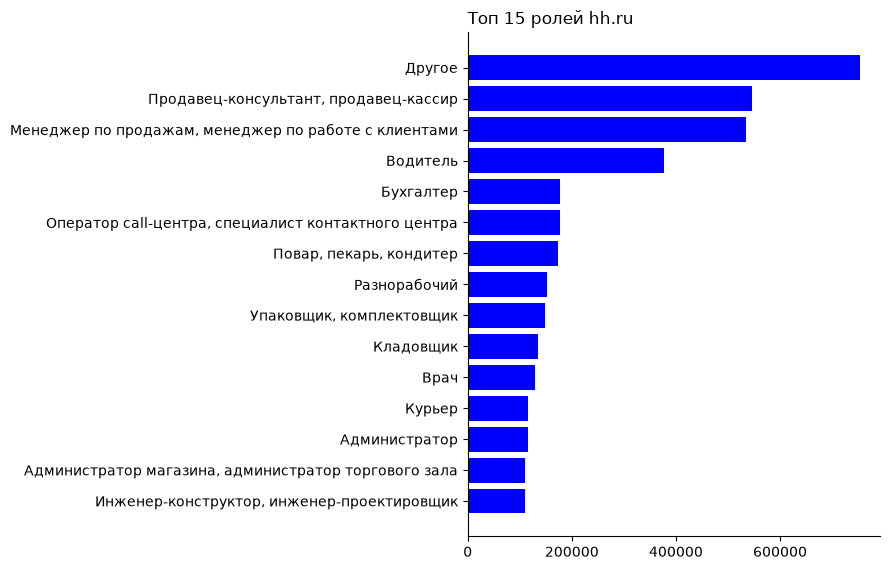

вакансий разработчиков 87803 разных ролей 174


In [11]:
def bar_chart(frame: pd.DataFrame, label_column: str, value_column: str, title: str, file_name: str) -> None:
    figure, axis = plt.subplots(figsize=(9, 0.32 * len(frame) + 1))
    
    axis.barh(frame[label_column][::-1], frame[value_column][::-1], color=BLUE)
    axis.set_title(title, loc="left")
    axis.grid(axis="x", color="white")
    axis.set_axisbelow(True)
    axis.ticklabel_format(axis="x", style="plain")
    axis.locator_params(axis="x", nbins=5)
    figure.tight_layout()
    figure.savefig(OUT / file_name, dpi=150)
    plt.show()


roles = con.sql("SELECT role, count(*) AS vacancies FROM v WHERE role IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 15").df()
bar_chart(roles, "role", "vacancies", "Топ 15 ролей hh.ru", "eda_roles.png")
developer_count, role_count = con.execute("""SELECT count(*) FILTER (WHERE role = 'Программист, разработчик'),
                                                 count(DISTINCT role) FROM v""").fetchall()[0]
print("вакансий разработчиков", developer_count, "разных ролей", role_count)

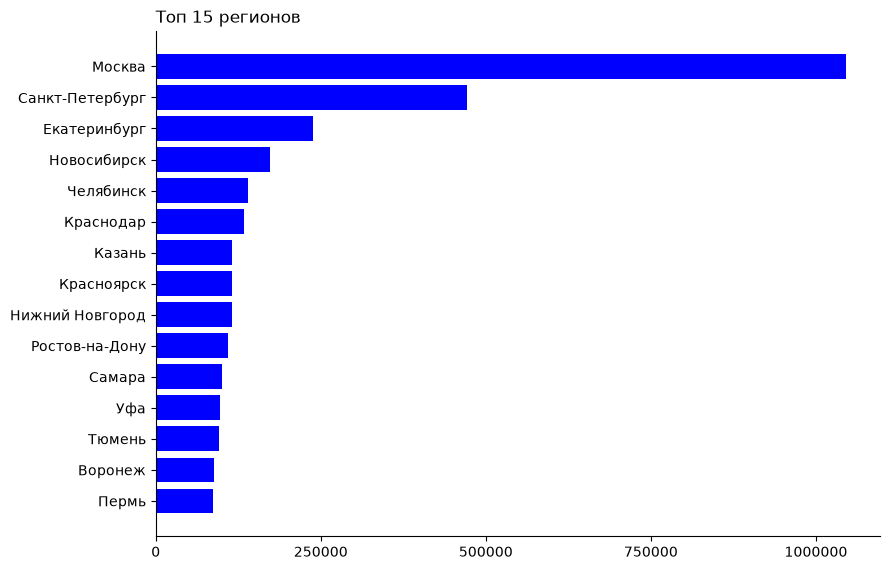

In [12]:
areas = con.sql("SELECT area, count(*) AS vacancies FROM v WHERE area IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 15").df()
bar_chart(areas, "area", "vacancies", "Топ 15 регионов", "eda_areas.png")

In [13]:
print(con.sql("SELECT experience, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df())

print(con.sql("SELECT schedule, count(*) AS vacancies FROM v GROUP BY ALL ORDER BY ALL").df())

           experience  vacancies
0         Более 6 лет     108787
1           Нет опыта    2947161
2  От 1 года до 3 лет    3097397
3       От 3 до 6 лет     965922
4                 NaN      71807
           schedule  vacancies
0    Вахтовый метод     600547
1     Гибкий график     433402
2       Полный день    4619811
3    Сменный график     992814
4  Удаленная работа     472693
5               NaN      71807


вакансий hh 7191074
с навыками 47.6 % вакансий
в среднем навыков у вакансии, где они есть 6.06


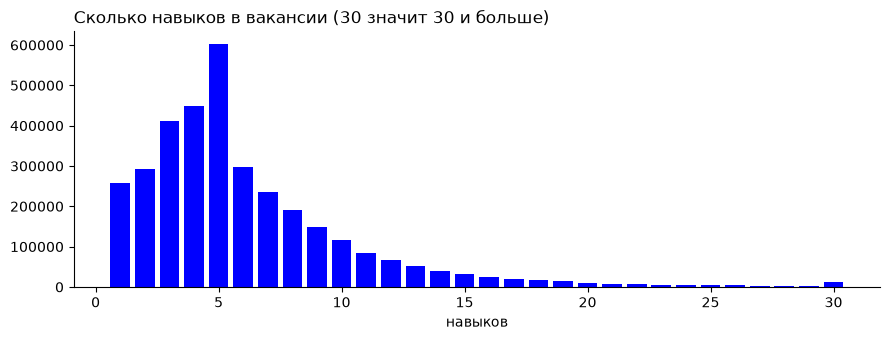

In [14]:
vacancy_count, with_skills_pct, skills_mean = con.execute("""SELECT count(*), round(100 * avg((len(skill_ids) > 0)::INT), 1),
                                                                    round(avg(len(skill_ids)) FILTER (WHERE len(skill_ids) > 0), 2)
                                                             FROM v""").fetchall()[0]
print("вакансий hh", vacancy_count)
print("с навыками", with_skills_pct, "% вакансий")
print("в среднем навыков у вакансии, где они есть", skills_mean)
skill_counts = con.sql("SELECT least(len(skill_ids), 30) AS n, count(*) AS vacancies FROM v WHERE len(skill_ids) > 0 GROUP BY 1 ORDER BY 1").df()
figure, axis = plt.subplots(figsize=(9, 3.5))
axis.bar(skill_counts["n"], skill_counts["vacancies"], color=BLUE)
axis.set_title("Сколько навыков в вакансии (30 значит 30 и больше)", loc="left")

axis.set_xlabel("навыков")
figure.tight_layout()
figure.savefig(OUT / "eda_skills_count.png", dpi=150)
plt.show()

In [15]:
months = con.sql("SELECT strftime(published_at, '%Y-%m') AS month, count(*) AS vacancies FROM v GROUP BY 1 ORDER BY 1").df()
print(months)

      month  vacancies
0   2023-11         28
1   2023-12     441082
2   2024-01     465049
3   2024-02     752457
4   2024-03     847536
5   2024-04     271293
6   2024-05     648338
7   2024-06     601343
8   2024-07     879847
9   2024-08    1253355
10  2024-09     958939
11      NaN      71807


## 4. Зарплатная вилка

In [16]:
fork = con.sql("""
    SELECT CASE WHEN salary_from IS NULL AND salary_to IS NULL THEN '1 нет зарплаты'
                WHEN salary_to IS NULL THEN '2 только от'
                WHEN salary_from IS NULL THEN '3 только до'
                ELSE '4 от и до' END AS fork,
           count(*) AS vacancies
    FROM v GROUP BY ALL ORDER BY ALL""").df()
    
fork["%"] = (100 * fork["vacancies"] / fork["vacancies"].sum()).round(1)
fork

,fork,vacancies,%
0,1 нет зарплаты,1130419,15.7
1,2 только от,2701712,37.6
2,3 только до,352253,4.9
3,4 от и до,3006690,41.8


In [17]:
print(con.sql("""SELECT currency, count(*) AS vacancies FROM v
                 WHERE salary_from IS NOT NULL OR salary_to IS NOT NULL GROUP BY ALL ORDER BY 2 DESC""").df())
print(con.sql("""SELECT gross, count(*) AS vacancies FROM v
                 WHERE currency = 'RUR' GROUP BY ALL ORDER BY ALL""").df())

  currency  vacancies
0      RUR    6043062
1      USD       6160
2      KZT       5204
3      BYR       4464
4      EUR       1009
5      UZS        622
6      KGS        114
7      AZN         10
8      GEL          7
9      UAH          3
   gross  vacancies
0  false    3886776
1   true    2152385
2    NaN       3901


## 5. Рынок IT

IT это раздел hh "Информационные технологии"

Границы беру от 10000, у IT ролей границы меньше 10000 в 0.2% рублёвых вакансий. Недостающую границу восстанавливаю через k, это медиана отношения "до/от" по вакансиям роли с обеими границами, у каждой роли своё k, дальше беру середину и перевожу net в gross. Вакансии hh вышли с 2023-11-13 по 2024-09-15, значит шкала НДФЛ одна: 13% с дохода до 5 млн в год и 15% сверху, в месяц это net до 362500

In [18]:
IT_ROLES = ["BI-аналитик, аналитик данных", "DevOps-инженер", "Аналитик", "Арт-директор, креативный директор",
            "Бизнес-аналитик", "Гейм-дизайнер", "Дата-сайентист", "Дизайнер, художник",
            "Директор по информационным технологиям (CIO)", "Менеджер продукта", "Методолог", "Программист, разработчик",
            "Продуктовый аналитик", "Руководитель группы разработки", "Руководитель отдела аналитики",
            "Руководитель проектов", "Сетевой инженер", "Системный администратор", "Системный аналитик",
            "Системный инженер", "Специалист по информационной безопасности", "Специалист технической поддержки",
            "Тестировщик", "Технический директор (CTO)", "Технический писатель"]

con.execute("""
CREATE OR REPLACE TEMP TABLE market AS
WITH hh AS (
    SELECT role, area, experience, schedule, gross,
           CASE WHEN role = 'Программист, разработчик' THEN lower(name) END AS name,
           CASE WHEN currency = 'RUR' AND salary_from >= 10000 THEN salary_from END AS salary_from,
           CASE WHEN currency = 'RUR' AND salary_to >= 10000 THEN salary_to END AS salary_to
    FROM v
), ratio AS (
    SELECT role, median(salary_to / salary_from) AS k FROM hh
    WHERE salary_from IS NOT NULL AND salary_to IS NOT NULL GROUP BY role
), point AS (
    SELECT hh.*, ratio.k,
           (coalesce(salary_from, salary_to / ratio.k) + coalesce(salary_to, salary_from * ratio.k)) / 2 AS point
    FROM hh LEFT JOIN ratio USING (role)
)
SELECT *, coalesce(role IN (SELECT unnest($roles)), false) AS it,
       CASE WHEN gross = 'false' AND point <= 362500 THEN point / 0.87
            WHEN gross = 'false' THEN (5000000 + (12 * point - 4350000) / 0.85) / 12
            ELSE point END AS salary
FROM point
""", {"roles": IT_ROLES})

con.sql("""SELECT CASE WHEN it THEN 'IT' ELSE 'остальной hh' END AS segment, count(*) AS vacancies,
                  round(100 * count(*) / sum(count(*)) OVER (), 1) AS share_pct,
                  round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                  round(median(salary)) AS median_gross,
                  round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) AS median_1_3_gross,
                  round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) AS median_3_gross,
                  round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                  round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                  round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct,
                  round(100 * avg((experience = 'Нет опыта')::INT), 1) AS no_experience_pct,
                  round(100 * avg((area IN ('Москва', 'Санкт-Петербург'))::INT), 1) AS moscow_spb_pct
           FROM market GROUP BY 1 ORDER BY 1""").df()

,segment,vacancies,share_pct,with_salary_pct,median_gross,median_1_3_gross,median_3_gross,remote_pct,experience_1_3_pct,experience_3_pct,no_experience_pct,moscow_spb_pct
0,IT,352871,4.9,48.9,95000.0,94828.0,189655.0,23.1,47.7,37.4,14.9,48.3
1,остальной hh,6838203,95.1,85.6,78818.0,86207.0,124138.0,5.8,43.3,13.9,42.8,19.9


Роли внутри IT по числу вакансий

                                            role  vacancies  it_share_pct     k  with_salary_pct       p25  median_gross       p75  median_1_3_gross  median_3_gross  remote_pct  experience_1_3_pct  \
0                       Программист, разработчик      87803          24.9  1.43             45.1   97701.0      164943.0  241379.0          139573.0        229885.0        28.2                42.5   
1               Специалист технической поддержки      49145          13.9  1.29             72.3   45977.0       54598.0   72250.0           65681.0        114286.0        41.8                46.0   
2                                       Аналитик      30112           8.5  1.31             39.0   66313.0       95376.0  155172.0           97701.0        198939.0        21.3                56.9   
3                        Системный администратор      29723           8.4  1.20             65.2   57471.0       75862.0  105364.0           75862.0        110000.0         4.9                59.7   


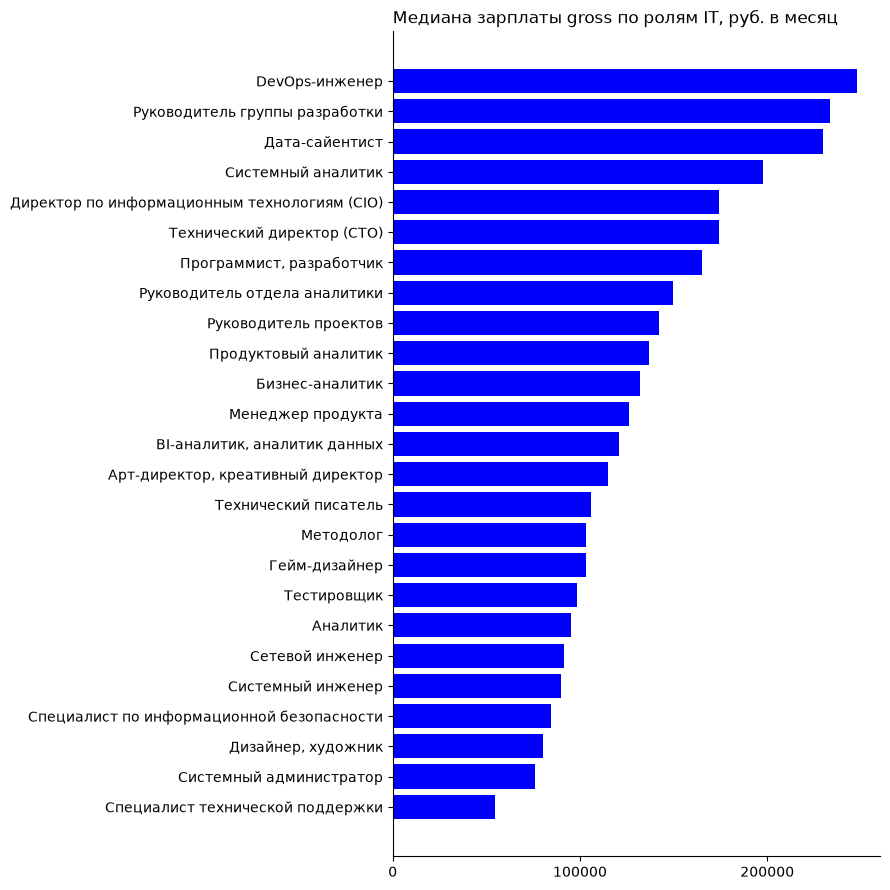

In [19]:
it_roles = con.sql("""SELECT role, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS it_share_pct,
                             round(any_value(k), 2) AS k, round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                             round(quantile_cont(salary, 0.25)) AS p25, round(median(salary)) AS median_gross,
                             round(quantile_cont(salary, 0.75)) AS p75,
                             round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) AS median_1_3_gross,
                             round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) AS median_3_gross,
                             round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                             round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                             round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct
                      FROM market WHERE it GROUP BY role ORDER BY vacancies DESC""").df()
print(it_roles)
print("ранговая корреляция медианы и доли вакансий с зарплатой по ролям",
      round(it_roles["median_gross"].rank().corr(it_roles["with_salary_pct"].rank()), 2))
bar_chart(it_roles.sort_values("median_gross", ascending=False), "role", "median_gross",
          "Медиана зарплаты gross по ролям IT, руб. в месяц", "it_roles_salary.png")

Языки у разработчиков: язык ищу в названии вакансий роли "Программист, разработчик", одна вакансия может попасть в несколько языков. Go тут ищу по названию, поэтому вакансий меньше, чем в варианте, где я беру ещё вакансии с Go в навыках

In [20]:
WORD = "(^|[^a-zа-яё0-9_])"
END = "([^a-zа-яё0-9_]|$)"
LANGUAGES = {
    "Python": WORD + "(python|питон)" + END,
    "Java": WORD + "java" + END,
    "JavaScript, TypeScript, frontend": WORD + "(javascript|typescript|js|ts|node|nodejs|react|vue|angular|frontend|фронтенд)" + END,
    "PHP": WORD + "php" + END,
    "1С": WORD + "(1с|1c)" + END,
    "C#, .NET": "c#|с#|\\.net",
    "C++": "c\\+\\+|с\\+\\+",
    "Go": duckdb_job.NAME_GO.strip("'"),
    "Kotlin, Android": WORD + "(kotlin|android)" + END,
    "Swift, iOS": WORD + "(swift|ios)" + END,
    "Ruby": WORD + "ruby" + END,
    "Rust": WORD + "rust" + END,
    "Scala": WORD + "scala" + END,
}
developers_total = con.execute("SELECT count(*) FROM market WHERE role = 'Программист, разработчик'").fetchall()[0][0]
language_rows = []

for language, pattern in LANGUAGES.items():
    language_rows.append(con.execute("""SELECT ? AS language, count(*) AS vacancies,
                                               round(100 * count(salary) / count(*), 1) AS with_salary_pct,
                                               round(median(salary)) AS median_gross,
                                               CASE WHEN count(salary) FILTER (WHERE experience = 'От 1 года до 3 лет') >= 10
                                                    THEN round(median(salary) FILTER (WHERE experience = 'От 1 года до 3 лет')) END AS median_1_3_gross,
                                               CASE WHEN count(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет')) >= 10
                                                    THEN round(median(salary) FILTER (WHERE experience IN ('От 3 до 6 лет', 'Более 6 лет'))) END AS median_3_gross,
                                               round(100 * avg((schedule = 'Удаленная работа')::INT), 1) AS remote_pct,
                                               round(100 * avg((experience = 'От 1 года до 3 лет')::INT), 1) AS experience_1_3_pct,
                                               round(100 * avg((experience IN ('От 3 до 6 лет', 'Более 6 лет'))::INT), 1) AS experience_3_pct
                                        FROM market WHERE role = 'Программист, разработчик' AND regexp_matches(name, ?)""",
                                     [language, pattern]).df())

languages = pd.concat(language_rows).sort_values("vacancies", ascending=False).reset_index(drop=True)
languages.insert(2, "developers_pct", (100 * languages["vacancies"] / developers_total).round(1))
print("вакансий разработчиков", developers_total)
languages

вакансий разработчиков 87803


,language,vacancies,developers_pct,with_salary_pct,median_gross,median_1_3_gross,median_3_gross,remote_pct,experience_1_3_pct,experience_3_pct
0,1С,21244,24.2,60.3,182143.0,167488.0,230296.0,27.1,47.9,42.7
1,"JavaScript, TypeScript, frontend",9219,10.5,40.8,170000.0,130000.0,235000.0,36.3,39.2,55.9
2,Java,6100,6.9,20.8,219300.0,166092.0,281609.0,35.0,25.5,68.1
3,PHP,5379,6.1,56.9,167488.0,139573.0,218391.0,42.1,45.2,49.0
4,"C#, .NET",4355,5.0,33.1,201149.0,139573.0,255000.0,37.8,33.0,62.1
5,Python,3897,4.4,34.2,189655.0,154265.0,250000.0,31.5,37.2,58.1
6,C++,3462,3.9,34.5,201149.0,149425.0,241379.0,19.2,31.1,63.9
7,Go,2565,2.9,23.9,293103.0,212644.0,344828.0,35.8,26.5,71.2
8,"Kotlin, Android",2036,2.3,29.1,229885.0,167488.0,301724.0,35.7,31.6,64.2
9,"Swift, iOS",1127,1.3,28.6,208128.0,150776.0,293103.0,36.1,30.8,62.6


IT по регионам: топ 10 регионов по числу вакансий IT, доля IT среди всех вакансий региона и медианы

In [21]:
it_regions = con.sql("""SELECT area, count(*) FILTER (WHERE it) AS it_vacancies,
                  round(100 * count(*) FILTER (WHERE it) / sum(count(*) FILTER (WHERE it)) OVER (), 1) AS of_all_it_pct,
                  round(100 * count(*) FILTER (WHERE it) / count(*), 1) AS it_in_region_pct,
                  round(median(salary) FILTER (WHERE it)) AS it_median_gross,
                  round(median(salary) FILTER (WHERE NOT it)) AS other_median_gross,
                  round(100 * avg((schedule = 'Удаленная работа')::INT) FILTER (WHERE it), 1) AS it_remote_pct
           FROM market GROUP BY area ORDER BY it_vacancies DESC LIMIT 10""").df()
con.execute("DROP TABLE market")
it_regions

,area,it_vacancies,of_all_it_pct,it_in_region_pct,it_median_gross,other_median_gross,it_remote_pct
0,Москва,133338,37.8,12.8,160920.0,105776.0,24.0
1,Санкт-Петербург,37059,10.5,7.9,121000.0,89080.0,21.4
2,Екатеринбург,13731,3.9,5.8,96177.0,80179.0,20.6
3,Новосибирск,10184,2.9,5.9,97701.0,79759.0,20.8
4,Казань,8055,2.3,6.9,91954.0,75758.0,28.4
5,Нижний Новгород,7271,2.1,6.3,85000.0,71924.0,26.0
6,Краснодар,6477,1.8,4.8,83744.0,79639.0,25.8
7,Самара,5307,1.5,5.3,75862.0,71167.0,26.1
8,Ростов-на-Дону,5089,1.4,4.7,80000.0,74713.0,25.5
9,Воронеж,4773,1.4,5.4,75000.0,68966.0,24.6


Эх верните мой 2024...

IT это 4.9% вакансий hh, и больше там платят опытным: с опытом 1-3 года медиана выше остального рынка на 10%, от 3 лет на 53%. Go восьмой язык по числу вакансий и самый дорогой из крупных при одинаковом опыте, с опытом 1-3 года 212644 против 167488 у следующих за ним

## 6. Вакансии Go

Либо в названии есть Go в любом написании: go, golang, goland, go-lang, голанг, голэнг, в том числе с русской о или а внутри, как в "Gо Developer", русское "го" считаю только рядом со словами "разработчик" или "программист", иначе в выборку попадают "ГО и ЧС" и "1-го", либо Go стоит в навыках, а в названии нет другого языка или frontend (Python, PHP, Java, C#, C++, Node, JS и т.д.)

Навыки режу по ";", перевожу в нижний регистр и обрезаю пробелы, golang, go lang, программирование на go и похожее свожу к go, дубли внутри вакансии убираю

In [22]:
con.execute(duckdb_job.fill("""
CREATE OR REPLACE TEMP TABLE developers AS
SELECT *, regexp_matches(lower(name), NAME_GO) AS name_go,
       list_contains(skills, 'go') AS skill_go,
       regexp_matches(lower(name), OTHER_LANGUAGE) AS other_language
FROM (
    SELECT *, list_distinct(list_filter(
               list_transform(string_split(lower(key_skills), ';'), lambda x:
                   CASE WHEN regexp_matches(trim(x, ' '), SKILL_GO) THEN 'go' ELSE trim(x, ' ') END),
               lambda x: x <> '')) AS skills
    FROM v WHERE role = 'Программист, разработчик')
"""))
con.sql("""SELECT name_go AS go_в_названии, skill_go AS go_в_навыках, other_language AS другой_язык_в_названии,
                  count(*) AS vacancies, name_go OR (skill_go AND NOT other_language) AS берём
           FROM developers WHERE name_go OR skill_go GROUP BY ALL ORDER BY ALL""").df()

,go_в_названии,go_в_навыках,другой_язык_в_названии,vacancies,берём
0,False,True,False,340,True
1,False,True,True,231,False
2,True,False,False,685,True
3,True,False,True,86,True
4,True,True,False,1604,True
5,True,True,True,190,True


Какие названия попадают только по навыку и какие из них отсеиваются

In [23]:
print(con.sql("""SELECT name, count(*) AS vacancies FROM developers
                 WHERE skill_go AND NOT name_go AND NOT other_language GROUP BY 1 ORDER BY 2 DESC LIMIT 10""").df())
                 
print(con.sql("""SELECT name, count(*) AS vacancies FROM developers
                 WHERE skill_go AND NOT name_go AND other_language GROUP BY 1 ORDER BY 2 DESC LIMIT 10""").df())

                                                name  vacancies
0                                Backend-разработчик         27
1                         Стажер-разработчик бэкенда         19
2  Backend-разработчик (Middle) в команду сбора и...          8
3                                Backend разработчик          8
4                     Разработчик серверной части ПО          6
5  Backend-разработчик (Middle) в команду открыты...          5
6                                Ведущий разработчик          5
7                                   VOIP разработчик          5
8           Старший бэкенд-разработчик в Образование          5
9  Senior backend разработчик / Ведущий backend и...          5
                                                name  vacancies
0                               С# Backend Developer          7
1                                Node.js разработчик          6
2                                 Разработчик NodeJS          6
3                                    PHP

Срез Go сохраняю в бакет, s3://hh-lake/variant/go_vacancies.parquet

In [24]:
con.execute("""CREATE OR REPLACE TEMP TABLE go AS
               SELECT vacancy_id, source, published_at, area, employer_id, name, salary_from, salary_to, currency, gross,
                      experience, schedule, employment, list_sort(skills) AS skills
               FROM developers WHERE name_go OR (skill_go AND NOT other_language)""")
con.execute("COPY go TO 's3://hh-lake/variant/go_vacancies.parquet' (FORMAT parquet)")
variant = con.sql("SELECT * FROM go ORDER BY vacancy_id").df()
variant["skills"] = variant["skills"].map(list)
print("вакансий Go", len(variant), "источники", variant["source"].value_counts().to_dict())

вакансий Go 2905 источники {'hh': 2905}


In [25]:
print(con.sql("""SELECT CASE WHEN salary_from IS NULL AND salary_to IS NULL THEN '1 нет зарплаты'
                             WHEN salary_to IS NULL THEN '2 только от'
                             WHEN salary_from IS NULL THEN '3 только до'
                             ELSE '4 от и до' END AS fork, currency, count(*) AS vacancies
                 FROM go GROUP BY ALL ORDER BY ALL""").df())
print(con.sql("SELECT experience, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct FROM go GROUP BY 1 ORDER BY 2 DESC").df())
print(con.sql("SELECT schedule, count(*) AS vacancies, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct FROM go GROUP BY 1 ORDER BY 2 DESC").df())

             fork currency  vacancies
0  1 нет зарплаты      NaN       2124
1     2 только от      RUR        235
2     2 только от      USD          7
3     3 только до      EUR          2
4     3 только до      RUR        196
5     3 только до      USD         14
6       4 от и до      KZT          3
7       4 от и до      RUR        298
8       4 от и до      USD         26
           experience  vacancies   pct
0       От 3 до 6 лет       1817  62.5
1  От 1 года до 3 лет        794  27.3
2         Более 6 лет        201   6.9
3           Нет опыта         93   3.2
           schedule  vacancies   pct
0       Полный день       1772  61.0
1  Удаленная работа        989  34.0
2     Гибкий график        142   4.9
3    Сменный график          2   0.1


               area  vacancies  with_rub_salary  with_skills
0            Москва       1750              390         1321
1   Санкт-Петербург        411              100          329
2      Екатеринбург         93               24           67
3   Нижний Новгород         76               11           57
4       Новосибирск         72               19           60
5            Казань         67               21           55
6         Краснодар         33               13           29
7    Ростов-на-Дону         32               15           22
8            Самара         27                7           22
9            Рязань         16                5            9
10           Алматы         14                0           11
11          Воронеж         14                7           12
12        Ульяновск         14                8           13
13      Калининград         12                4            9
14            Пенза         12                2           11


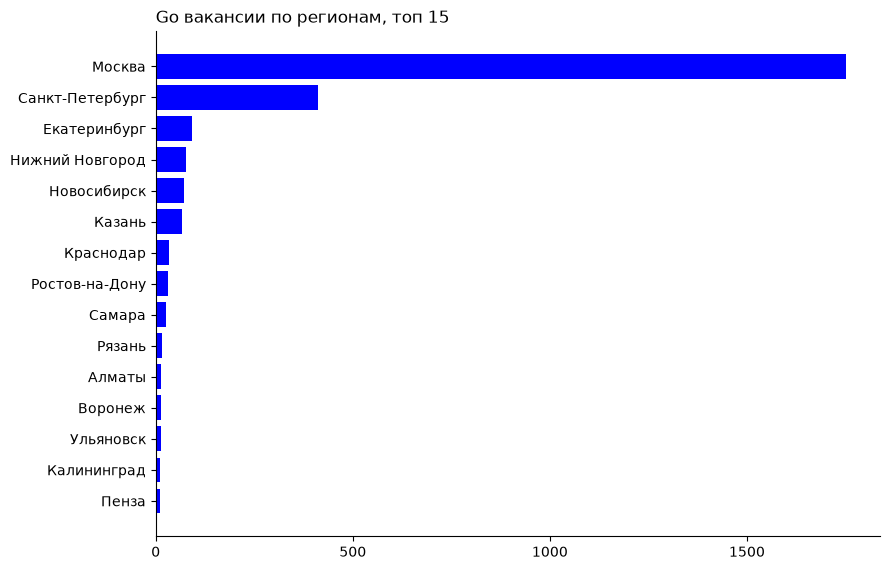

In [26]:
go_areas = con.sql("""SELECT area, count(*) AS vacancies,
                             count(*) FILTER (WHERE currency = 'RUR') AS with_rub_salary,
                             count(*) FILTER (WHERE len(skills) > 0) AS with_skills
                      FROM go GROUP BY 1 ORDER BY 2 DESC LIMIT 15""").df()
                      
print(go_areas)
bar_chart(go_areas, "area", "vacancies", "Go вакансии по регионам, топ 15", "go_areas.png")

In [27]:
go_total, go_employers, go_skills_mean, go_without_skills = con.execute("""SELECT count(*), count(DISTINCT employer_id),
                                round(avg(len(skills)) FILTER (WHERE len(skills) > 0), 2),
                                count(*) FILTER (WHERE len(skills) = 0)
                         FROM go""").fetchall()[0]
print("вакансий", go_total, "работодателей", go_employers, "навыков в среднем у вакансий с навыками", go_skills_mean,
      "без навыков", go_without_skills)
top_employers = con.sql("SELECT employer_id, count(*) AS vacancies FROM go GROUP BY 1 ORDER BY 2 DESC LIMIT 5").df()
print(top_employers)
print("доля топ 5 работодателей", round(100 * top_employers["vacancies"].sum() / len(variant), 1), "%")

вакансий 2905 работодателей 765 навыков в среднем у вакансий с навыками 5.96 без навыков 665
  employer_id  vacancies
0        2180        217
1       87021         88
2        3529         84
3        1740         74
4       78638         56
доля топ 5 работодателей 17.9 %
